# Week 5 - Day 1

# Logistic Regression: Classification

In Week 4, we learned how Machine Learning can predict continuous values with **Regression** and how K-Means can discover groups without labels.

Today, we move to **Classification**.

We will build a model that learns to place observations into categories.


o## Learning Objectives

By the end of this lesson, you will be able to:

- Explain classification in simple terms.
- Distinguish classification from regression.
- Explain what Logistic Regression is.
- Understand binary classification.
- Understand the sigmoid function and probability.
- Prepare a classification dataset.
- Split data into training and testing sets.
- Train a Logistic Regression model.
- Make predictions and probabilities.
- Evaluate a classifier using accuracy.
- Read and interpret a confusion matrix.
- Explain true positives, true negatives, false positives, and false negatives.
- Compare different classification examples.
- Understand important limitations and model settings.


## Why This Lesson Matters

Imagine a bank receives a loan application.

The bank does not want to predict a continuous number like house price. It wants to answer a category question:

**Approve or Reject?**

That is a classification problem.

Today, we will teach a Machine Learning model to make this type of decision from data.


## Recap: Regression

In Week 4, Linear Regression predicted a **continuous value**.

Example:

`Area + Rooms → House Price`

The answer could be:

`₦45,000,000`

or:

`₦52,500,000`

There are many possible numerical values.


## Classification

**Classification is a supervised learning task where a model learns to assign observations to predefined categories or classes.**

Examples:

- Spam / Not Spam
- Pass / Fail
- Churn / No Churn
- Fraud / Not Fraud
- Disease Present / Disease Absent


## Regression vs Classification

| Regression | Classification |
|---|---|
| Predicts continuous values | Predicts categories |
| Example: house price | Example: spam/not spam |
| Output can be many numerical values | Output belongs to one of the classes |
| Linear Regression | Logistic Regression |

The name **Logistic Regression** can be confusing because it is mainly used for classification.


## What is Binary Classification?

**Binary Classification is classification where there are two possible classes.**

For example:

`0 = Not Spam`

`1 = Spam`

Or:

`0 = Fail`

`1 = Pass`

Today's main example will use binary classification.


## What is Logistic Regression?

**Logistic Regression is a supervised Machine Learning algorithm commonly used for binary classification.**

Instead of directly producing a continuous output like Linear Regression, it estimates the probability that an observation belongs to a class.


## Real-Life Example

Imagine we want to predict whether a student will pass an exam.

We may have:

- Study Hours
- Attendance

The model receives those features and estimates something like:

`Probability of Pass = 0.87`

We then convert that probability into a class such as:

`1 = Pass`


## The Important Difference

Logistic Regression does not simply say:

> "This student is 1."

Internally, it first produces a probability.

For example:

`0.87 → likely class 1`

`0.22 → likely class 0`

This probability is then converted into a class prediction.


# Part 1 — Understanding the Sigmoid Function

The key mathematical idea behind Logistic Regression is the **sigmoid function**.

You do not need advanced mathematics to use the model, but you should understand what the function is doing.


## What is the Sigmoid Function?

**The sigmoid function converts a numerical score into a value between 0 and 1.**

That makes it useful for representing probability.


## Why Do We Need It?

A model could produce any numerical value:

`-4`, `-1`, `0`, `2`, `5`, etc.

Those values are not probabilities.

The sigmoid function transforms them into values between:

`0 and 1`


## Interpreting Probability

For a binary classification problem:

- `0.10` → low probability of class 1
- `0.50` → uncertain boundary
- `0.90` → high probability of class 1

The exact meaning depends on the problem and the decision threshold.


## The Default Threshold

Scikit-learn Logistic Regression normally uses a threshold of **0.5** for binary class prediction.

So, conceptually:

`Probability >= 0.5 → class 1`

`Probability < 0.5 → class 0`

We will later change this threshold to see why it matters.


## Visualize the Sigmoid Function

Let's use NumPy and Matplotlib to see its shape.

This is a concept demonstration, not the Logistic Regression model itself.


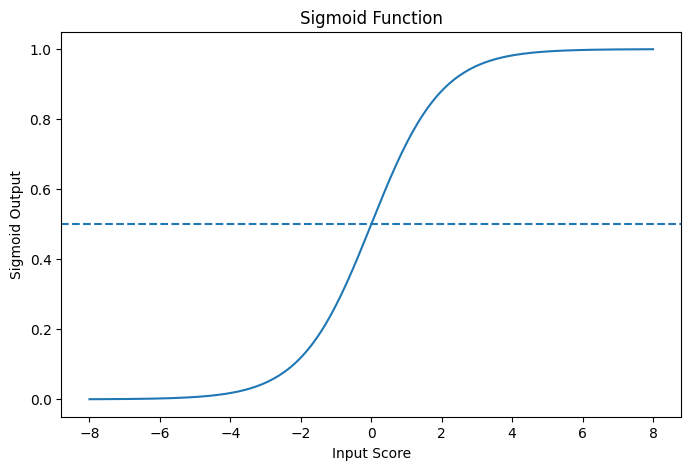

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

x = np.linspace(-8, 8, 200)
y = sigmoid(x)

plt.figure(figsize=(8, 5))
plt.plot(x, y)
plt.xlabel("Input Score")
plt.ylabel("Sigmoid Output")
plt.title("Sigmoid Function")
plt.axhline(0.5, linestyle="--")
plt.show()


## What Should You Notice?

The curve stays between 0 and 1.

As the input score increases, the sigmoid output moves closer to 1.

As the input score decreases, the output moves closer to 0.


## A Simple Sigmoid Example

Let's calculate the sigmoid of a few values.


In [2]:
values = [-5, -2, 0, 2, 5]

for value in values:
    print(value, "→", round(sigmoid(value), 4))


-5 → 0.0067
-2 → 0.1192
0 → 0.5
2 → 0.8808
5 → 0.9933


## What Does This Mean?

A large negative score produces a probability close to 0.

A large positive score produces a probability close to 1.

At `0`, the sigmoid produces `0.5`, which is the usual binary classification boundary.


# Part 2 — Our Classification Dataset

We will begin with a simple **student performance dataset**.

Our goal is:

> **Predict whether a student will pass based on Study Hours and Attendance.**


## Why Start With Students?

This example is easy to understand because the relationship is intuitive.

More study time and stronger attendance may provide useful information about whether a student passes.

The model will learn the pattern from the examples instead of us manually writing rules.


## Import Our Main Libraries

We need:

- **Pandas** → work with the dataset.
- **NumPy** → numerical operations.
- **Matplotlib** → visualization.
- **Scikit-learn** → train and evaluate the classification model.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully.")


Libraries imported successfully.


## Create `students.csv`

Just like we did with the previous datasets, we will create a small CSV so the notebook can run independently.

In a real project, this CSV could come from a school's database or an exported spreadsheet.


In [4]:
student_data = {
    "Student_ID": [f"S{i:03d}" for i in range(1, 41)],
    "Study_Hours": [
        1, 2, 1.5, 2.5, 3, 2, 3.5, 4, 3, 4.5,
        5, 4, 5.5, 6, 5, 6.5, 7, 6, 7.5, 8,
        2, 3, 2.5, 1, 3.5, 4.5, 5.5, 6.5, 7, 8.5,
        1.5, 2.5, 3.5, 4, 5, 6, 7, 8, 9, 10
    ],
    "Attendance": [
        55, 60, 58, 62, 65, 68, 64, 70, 72, 69,
        75, 73, 78, 80, 77, 82, 85, 84, 88, 90,
        52, 66, 61, 50, 71, 74, 79, 81, 86, 92,
        57, 63, 67, 76, 83, 87, 89, 94, 96, 98
    ],
    "Pass": [
        0, 0, 0, 0, 0, 0, 0, 1, 0, 1,
        1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
        0, 0, 0, 0, 1, 1, 1, 1, 1, 1,
        0, 0, 1, 1, 1, 1, 1, 1, 1, 1
    ]
}

students = pd.DataFrame(student_data)

students.to_csv("students.csv", index=False)

print("students.csv created successfully.")


students.csv created successfully.


## Load the CSV

The workflow is now the same as a real project:

**CSV → DataFrame → Inspect → Prepare → Train → Predict → Evaluate**


In [5]:
students = pd.read_csv("students.csv")

students.head()


,Student_ID,Study_Hours,Attendance,Pass
0,S001,1.0,55,0
1,S002,2.0,60,0
2,S003,1.5,58,0
3,S004,2.5,62,0
4,S005,3.0,65,0


## Inspect the Dataset

Always inspect your data before training a model.

We want to know:

- What columns exist?
- What type of data is present?
- Are there missing values?
- What does the target column look like?


In [6]:
students.info()


<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Student_ID   40 non-null     str    
 1   Study_Hours  40 non-null     float64
 2   Attendance   40 non-null     int64  
 3   Pass         40 non-null     int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 1.4 KB


## Check for Missing Values

A model should not be trained blindly.

We check whether any values are missing.


In [7]:
students.isnull().sum()


Student_ID     0
Study_Hours    0
Attendance     0
Pass           0
dtype: int64

## Check the Target Classes

Our target is `Pass`.

Let's see how many students belong to each class.


In [8]:
students["Pass"].value_counts()


Pass
1    25
0    15
Name: count, dtype: int64

## Why Check Class Counts?

Suppose we had:

`Pass = 38`

`Fail = 2`

A model could achieve 95% accuracy by predicting "Pass" almost every time.

That is why class distribution matters when evaluating classification models.


# Part 3 — Explore the Classification Problem

Before training the model, let's visualize the relationship between the features and the target.


## Scatter Plot: Study Hours vs Attendance

We can use colour to represent the target class.

This helps us see whether the two classes appear to have different patterns.


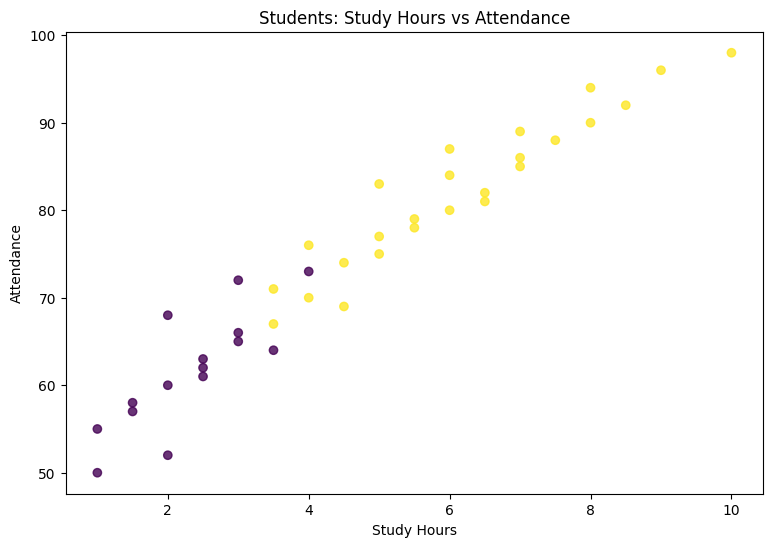

In [9]:
plt.figure(figsize=(9, 6))

plt.scatter(
    students["Study_Hours"],
    students["Attendance"],
    c=students["Pass"],
    alpha=0.8
)

plt.xlabel("Study Hours")
plt.ylabel("Attendance")
plt.title("Students: Study Hours vs Attendance")
plt.show()


## What Are We Looking For?

We are looking for whether the observations belonging to the two classes appear to occupy different regions.

A clear separation can make classification easier.

But a chart alone does not prove that the model will perform well.


## Why We Use These Two Features

Our question is:

> Can we predict whether a student passes using study time and attendance?

Therefore:

- `Study_Hours` → feature
- `Attendance` → feature
- `Pass` → target


In [10]:
X = students[["Study_Hours", "Attendance"]]
y = students["Pass"]

print("Features:")
display(X.head())

print("Target:")
display(y.head())


Features:


,Study_Hours,Attendance
0,1.0,55
1,2.0,60
2,1.5,58
3,2.5,62
4,3.0,65


Target:


0    0
1    0
2    0
3    0
4    0
Name: Pass, dtype: int64

## What is a Feature?

**A feature is an input variable used by a Machine Learning model to make a prediction.**

Here:

- Study Hours is a feature.
- Attendance is a feature.


## What is a Target?

**The target is the output the supervised learning model is trained to predict.**

Here:

`Pass` is the target.

It contains the known answers used during training.


# Part 4 — Training Data and Testing Data

We should not train and evaluate a model on exactly the same observations.

Instead, we divide the dataset into:

- **Training data**
- **Testing data**


## Why Split the Data?

Imagine teaching a student 20 questions and then testing them using those exact same 20 questions.

A high score would not tell us whether the student can answer new questions.

Machine Learning has the same problem.

We want to know whether the model can work on **unseen data**.


## Training Set

The training set is the data the model learns from.

We provide:

`X_train + y_train`

The model learns the relationship between the features and the target.


## Testing Set

The test set contains observations the model did not use while learning.

We use:

`X_test`

to make predictions and compare them with:

`y_test`


## The `train_test_split()` Function

Scikit-learn provides:

```python
train_test_split()
```

It randomly divides the dataset into training and testing portions.


## Why Use `test_size=0.2`?

`test_size=0.2` means approximately:

- 80% → training
- 20% → testing

This is a common starting point for small educational datasets.

The exact split depends on the project.


## Why Use `random_state=42`?

The split uses randomness.

A fixed `random_state` makes the same split reproducible.

Again, `42` is simply a commonly used example number. It is not mathematically special.


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 32
Testing samples: 8


## Why Did We Add `stratify=y`?

Because this is classification.

`stratify=y` helps preserve a similar class distribution in the training and testing sets.

For example, if the original dataset has both Pass and Fail students, we do not want the test set to accidentally contain almost only one class.


In [12]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Training class distribution:
Pass
1    20
0    12
Name: count, dtype: int64

Testing class distribution:
Pass
1    5
0    3
Name: count, dtype: int64


# Part 5 — Feature Scaling

Before training, we can standardize the numerical features.

This is especially useful when features are measured on different scales or when we want a consistent preprocessing workflow.


## Why Scale These Features?

Our features are:

- Study Hours → roughly 1–10
- Attendance → roughly 50–100

They are not on exactly the same scale.

Standardization puts them on a more comparable scale.


## StandardScaler

**StandardScaler transforms numerical features so they are centered around 0 and scaled according to their standard deviation.**

We introduced this idea during data preprocessing and K-Means.

Today we use it as part of a classification pipeline.


## Important Rule: Fit the Scaler Only on Training Data

We should not let information from the test set influence preprocessing.

So we do:

`fit_transform(X_train)`

and:

`transform(X_test)`

We do **not** fit the scaler separately on the test set.


In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data after scaling:")
print(X_train_scaled[:5])


Training data after scaling:
[[-0.69719249 -0.17242471]
 [-1.1346466  -1.19105686]
 [-1.1346466  -1.87014495]
 [ 0.8338969   0.5915494 ]
 [-0.25973838 -0.0875387 ]]


## Why Not `fit_transform()` on Both?

If we fit the scaler on the test data, we allow information from the test set to influence the preprocessing.

This is a form of **data leakage**.

We want the test set to remain genuinely unseen.


## What is Data Leakage?

**Data leakage happens when information that should be unavailable during training accidentally influences the model-building process.**

A simple rule:

> Learn preprocessing from the training data, then apply it to the test data.


# Part 6 — Train Our First Logistic Regression Model

Now we have:

- Features selected
- Target selected
- Data split
- Features scaled

We are ready to train the classifier.


## Create the Model

We use:

```python
LogisticRegression()
```

from Scikit-learn.

This creates the Logistic Regression classifier.


In [14]:
model = LogisticRegression(
    random_state=42
)

print(model)


LogisticRegression(random_state=42)


## Train the Model

The `.fit()` method teaches the model using the training data.

We provide:

`X_train_scaled`

and:

`y_train`


In [15]:
model.fit(
    X_train_scaled,
    y_train
)

print("Model training completed.")


Model training completed.


## What Did the Model Learn?

The model learned relationships between:

- Study Hours
- Attendance

and the target:

- Pass / Fail

It uses those learned relationships to classify new observations.


# Part 7 — Make Predictions

Now we give the model the test features it has never seen before.

The model will predict whether each student passes or fails.


In [16]:
predictions = model.predict(X_test_scaled)

predictions


array([1, 1, 0, 1, 0, 1, 0, 1])

## Compare Predictions With Actual Values

Let's place the actual and predicted values beside each other.


In [17]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": predictions
})

comparison


,Actual,Predicted
0,1,1
1,1,1
2,0,0
3,1,1
4,0,0
5,1,1
6,0,0
7,1,1


## Why Is This Comparison Useful?

It lets us see individual decisions.

For each test student:

- Did the model predict correctly?
- Did it predict the wrong class?


# Part 8 — Prediction Probabilities

Classification models can provide more information than just the final class.

Logistic Regression can give us the estimated probability for each class.


## `predict_proba()`

`predict_proba()` returns probabilities for each possible class.

For a binary problem, you will usually see two columns:

- Probability of class 0
- Probability of class 1


In [18]:
probabilities = model.predict_proba(X_test_scaled)

probabilities[:5]


array([[0.01061769, 0.98938231],
       [0.01602618, 0.98397382],
       [0.80958546, 0.19041454],
       [0.02602223, 0.97397777],
       [0.97711597, 0.02288403]])

## Put the Probabilities in a Table

This makes the output easier to understand.


In [19]:
probability_table = pd.DataFrame(
    probabilities,
    columns=["Probability_Fail", "Probability_Pass"]
)

probability_table.head()


,Probability_Fail,Probability_Pass
0,0.010618,0.989382
1,0.016026,0.983974
2,0.809585,0.190415
3,0.026022,0.973978
4,0.977116,0.022884


## Combine Everything

Let's see the actual class, predicted class, and probability of passing together.


In [20]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": predictions,
    "Probability_Pass": probabilities[:, 1]
})

results.round(3)


,Actual,Predicted,Probability_Pass
0,1,1,0.989
1,1,1,0.984
2,0,0,0.190
3,1,1,0.974
4,0,0,0.023
5,1,1,0.841
6,0,0,0.369
7,1,1,0.999


## Example Interpretation

If the model gives:

`Probability_Pass = 0.91`

it is strongly leaning toward Pass.

If it gives:

`Probability_Pass = 0.18`

it is strongly leaning toward Fail.

Probability gives us more information than the class label alone.


# Part 9 — The Classification Threshold

The default decision threshold is usually 0.5.

But the probability and the final class are not the same thing.

We can choose a different threshold depending on the problem.


## Default Rule

Conceptually:

```text
Probability of class 1 >= 0.5 → predict 1
Probability of class 1 < 0.5 → predict 0
```


In [21]:
default_predictions = (
    probabilities[:, 1] >= 0.5
).astype(int)

print(default_predictions)


[1 1 0 1 0 1 0 1]


## Try a 0.7 Threshold

Now we require stronger confidence before predicting class 1.


In [22]:
threshold_70_predictions = (
    probabilities[:, 1] >= 0.7
).astype(int)

print(threshold_70_predictions)


[1 1 0 1 0 1 0 1]


## Why Would We Change the Threshold?

Imagine a medical screening system.

A false negative could be more serious than a false positive.

In that situation, we may choose a threshold that helps identify more potential positive cases.

The appropriate threshold depends on the real-world cost of mistakes.


## Important Beginner Rule

Do not change the threshold just to make accuracy look better.

Choose a threshold based on the **problem and the consequences of errors**.


# Part 10 — Evaluate the Model

A model is not complete after training.

We need to evaluate how well it performs on unseen data.


## What is Accuracy?

**Accuracy is the proportion of predictions that the model classified correctly.**

Formula:

`Accuracy = Correct Predictions / Total Predictions`


## Simple Example

Suppose the model makes 20 predictions.

If 17 are correct:

`Accuracy = 17 / 20 = 0.85`

So the accuracy is:

**85%**


In [23]:
accuracy = accuracy_score(
    y_test,
    predictions
)

print("Accuracy:", round(accuracy, 3))
print("Accuracy percentage:", round(accuracy * 100, 2), "%")


Accuracy: 1.0
Accuracy percentage: 100.0 %


## Is Accuracy Always Enough?

No.

Accuracy can be misleading when classes are highly imbalanced.

For example, if 99% of transactions are not fraud, a model that predicts "not fraud" every time can achieve 99% accuracy while detecting no fraud.

That is why we need the confusion matrix and other metrics.


# Part 11 — Confusion Matrix

**A confusion matrix is a table that shows how a classification model's predictions compare with the actual classes.**

It helps us understand **what kinds of mistakes** the model is making.


## The Four Important Terms

For binary classification:

- **True Positive (TP):** Model predicts positive and the actual class is positive.
- **True Negative (TN):** Model predicts negative and the actual class is negative.
- **False Positive (FP):** Model predicts positive but the actual class is negative.
- **False Negative (FN):** Model predicts negative but the actual class is positive.


## Student Example

Suppose:

`1 = Pass`

`0 = Fail`

Then:

**True Positive:** Model predicts Pass and student actually passed.

**True Negative:** Model predicts Fail and student actually failed.

**False Positive:** Model predicts Pass but student actually failed.

**False Negative:** Model predicts Fail but student actually passed.


## Why Do False Positives and False Negatives Matter?

A mistake is not just a number.

The meaning depends on the application.

For example, in a student-support system, a false negative might mean failing to identify a student who actually needs academic support.


In [24]:
cm = confusion_matrix(
    y_test,
    predictions
)

cm


array([[3, 0],
       [0, 5]])

## Read the Matrix

For Scikit-learn's binary confusion matrix, the layout is:

| | Predicted 0 | Predicted 1 |
|---|---:|---:|
| Actual 0 | True Negative | False Positive |
| Actual 1 | False Negative | True Positive |

The exact numbers come from our test predictions.


## Visualize the Confusion Matrix

A visual representation makes the four outcomes easier to read.


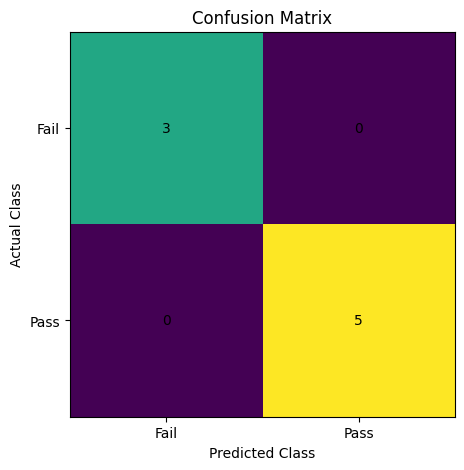

In [25]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks([0, 1], ["Fail", "Pass"])
plt.yticks([0, 1], ["Fail", "Pass"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()


## How to Interpret It

Look at each cell.

Ask:

- How many students who actually failed were predicted correctly?
- How many students who actually passed were predicted correctly?
- How many were incorrectly classified?

This is much more informative than looking at accuracy alone.


# Part 12 — Classification Report

Scikit-learn provides a useful summary called:

`classification_report()`

It gives us several evaluation metrics.


## Important Classification Metrics

The report includes:

- Precision
- Recall
- F1-score
- Support

These metrics help us understand performance beyond simple accuracy.


## Precision

**Precision asks:**

> Of all observations the model predicted as positive, how many were actually positive?

High precision means the model makes relatively few false-positive predictions.


## Recall

**Recall asks:**

> Of all the observations that were actually positive, how many did the model correctly identify?

High recall means the model misses relatively few positive cases.


## F1-Score

**F1-score combines precision and recall into one measure.**

It is useful when we want a balance between:

- avoiding false positives
- avoiding false negatives


## Support

**Support is the number of actual observations belonging to each class in the evaluated dataset.**

It helps us understand how much data each metric is based on.


In [26]:
report = classification_report(
    y_test,
    predictions
)

print(report)


              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      1.00      1.00         5

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



## Accuracy vs Precision vs Recall

| Metric | Main Question |
|---|---|
| Accuracy | How many predictions were correct overall? |
| Precision | When the model says positive, how often is it right? |
| Recall | How many actual positives did the model find? |
| F1-score | How well are precision and recall balanced? |

No single metric is automatically the best for every problem.


# Part 13 — Looking Inside the Model

Logistic Regression also gives us coefficients.

These coefficients help us understand how the features influence the model's learned decision boundary.


## What is a Coefficient?

A coefficient represents the direction and strength of a feature's contribution to the model's underlying score.

A positive coefficient means increasing the feature tends to push the prediction toward class 1.

A negative coefficient pushes it toward class 0.

Because we standardized the features, comparing coefficient magnitudes is more meaningful than if the features were left on very different scales.


In [27]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

coefficients


,Feature,Coefficient
0,Study_Hours,1.608239
1,Attendance,1.228659


## Interpret the Coefficients Carefully

If `Study_Hours` has a positive coefficient, the model has learned that higher study hours are associated with a higher likelihood of class 1 in this dataset.

This does **not** automatically prove that studying more causes passing.

The model identifies statistical patterns; it does not establish causation.


## Why Did We Scale Before Comparing Coefficients?

If one feature were measured in very large units and another in small units, raw coefficient sizes could be difficult to compare.

Standardization makes the feature scales more comparable.


# Part 14 — Visualizing a Logistic Regression Decision Boundary

Because our dataset has only two features, we can visualize the model's decision boundary.

This helps us understand what the classifier is doing geometrically.


## What is a Decision Boundary?

**A decision boundary is the boundary that separates regions where the classifier predicts different classes.**

In a simple two-feature Logistic Regression model, the boundary is a line.


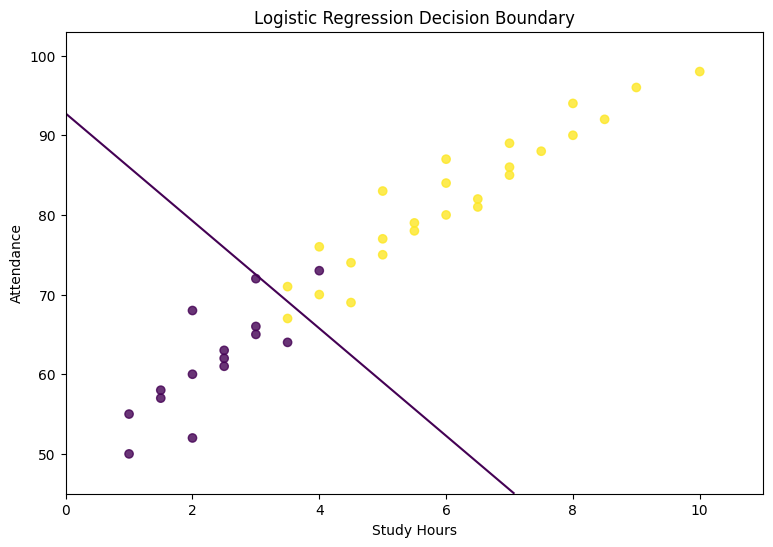

In [28]:
x_min, x_max = X["Study_Hours"].min() - 1, X["Study_Hours"].max() + 1
y_min, y_max = X["Attendance"].min() - 5, X["Attendance"].max() + 5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = pd.DataFrame({
    "Study_Hours": xx.ravel(),
    "Attendance": yy.ravel()
})

grid_scaled = scaler.transform(grid)

grid_probabilities = model.predict_proba(grid_scaled)[:, 1]

Z = grid_probabilities.reshape(xx.shape)

plt.figure(figsize=(9, 6))

plt.contour(
    xx,
    yy,
    Z,
    levels=[0.5]
)

plt.scatter(
    students["Study_Hours"],
    students["Attendance"],
    c=students["Pass"],
    alpha=0.8
)

plt.xlabel("Study Hours")
plt.ylabel("Attendance")
plt.title("Logistic Regression Decision Boundary")
plt.show()


## What Does the Line Represent?

The line represents the approximate region where the model's estimated probability of class 1 is around 0.5.

On one side, the model tends toward class 0.

On the other side, it tends toward class 1.


# Part 15 — Example 2: Customer Churn

Let's apply the same classification idea to a business problem.

Suppose a company wants to predict whether a customer will leave its service.


## What is Churn?

**Customer churn means a customer stops using or leaves a service.**

Our target could be:

`0 = Stayed`

`1 = Churned`


## Possible Features

We could use:

- Monthly Charges
- Tenure
- Number of Support Calls
- Contract Length

The important point is that the target is now a category.


In [29]:
churn_data = {
    "Customer_ID": [f"C{i:03d}" for i in range(1, 31)],
    "Tenure_Months": [
        2, 4, 6, 8, 10, 12, 14, 18, 20, 24,
        3, 5, 7, 9, 11, 15, 17, 19, 22, 26,
        1, 4, 6, 13, 16, 21, 23, 28, 30, 36
    ],
    "Monthly_Charges": [
        85, 80, 78, 75, 72, 70, 68, 65, 62, 60,
        90, 86, 82, 77, 73, 69, 66, 64, 61, 58,
        95, 88, 84, 71, 67, 63, 59, 55, 52, 50
    ],
    "Support_Calls": [
        7, 6, 8, 5, 6, 4, 5, 3, 4, 2,
        9, 7, 6, 5, 5, 4, 3, 3, 2, 2,
        10, 8, 7, 4, 4, 3, 2, 2, 1, 1
    ],
    "Churn": [
        1, 1, 1, 0, 0, 0, 0, 0, 0, 0,
        1, 1, 1, 0, 0, 0, 0, 0, 0, 0,
        1, 1, 1, 0, 0, 0, 0, 0, 0, 0
    ]
}

churn = pd.DataFrame(churn_data)

churn.to_csv("customer_churn.csv", index=False)

print("customer_churn.csv created successfully.")


customer_churn.csv created successfully.


## Inspect the Churn Dataset


In [30]:
churn = pd.read_csv("customer_churn.csv")

churn.head()


,Customer_ID,Tenure_Months,Monthly_Charges,Support_Calls,Churn
0,C001,2,85,7,1
1,C002,4,80,6,1
2,C003,6,78,8,1
3,C004,8,75,5,0
4,C005,10,72,6,0


## Select Features and Target

Our question is:

> Can we predict whether a customer will churn using tenure, monthly charges, and support calls?


In [31]:
X_churn = churn[
    ["Tenure_Months", "Monthly_Charges", "Support_Calls"]
]

y_churn = churn["Churn"]

X_churn.head()


,Tenure_Months,Monthly_Charges,Support_Calls
0,2,85,7
1,4,80,6
2,6,78,8
3,8,75,5
4,10,72,6


## Split the Churn Data


In [32]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_churn,
    y_churn,
    test_size=0.2,
    random_state=42,
    stratify=y_churn
)

print("Training:", len(Xc_train))
print("Testing:", len(Xc_test))


Training: 24
Testing: 6


## Scale the Churn Features


In [33]:
churn_scaler = StandardScaler()

Xc_train_scaled = churn_scaler.fit_transform(Xc_train)
Xc_test_scaled = churn_scaler.transform(Xc_test)


## Train the Churn Classifier


In [34]:
churn_model = LogisticRegression(
    random_state=42
)

churn_model.fit(
    Xc_train_scaled,
    yc_train
)

print("Churn model trained.")


Churn model trained.


## Predict Churn


In [35]:
churn_predictions = churn_model.predict(
    Xc_test_scaled
)

churn_predictions


array([0, 1, 0, 0, 0, 1])

## Evaluate Churn

We use the same classification evaluation workflow.

This is important:

**The model changed, but the Machine Learning workflow stayed mostly the same.**


In [36]:
churn_accuracy = accuracy_score(
    yc_test,
    churn_predictions
)

print(
    "Churn Accuracy:",
    round(churn_accuracy, 3)
)


Churn Accuracy: 1.0


In [37]:
print(
    confusion_matrix(
        yc_test,
        churn_predictions
    )
)


[[4 0]
 [0 2]]


In [38]:
print(
    classification_report(
        yc_test,
        churn_predictions
    )
)


              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



## Why This Example Is Useful

We have now used Logistic Regression for two different problems:

1. Student pass/fail.
2. Customer churn/no churn.

The algorithm is the same.

The **business question, features, target, and interpretation** change.


# Part 16 — Example 3: Spam vs Not Spam

Another common binary classification problem is email spam detection.

The target could be:

`0 = Not Spam`

`1 = Spam`


## Important Difference

Real email messages are text.

Logistic Regression cannot directly process raw text.

The text must first be converted into numerical features.

We will cover full text preprocessing and TF-IDF later in the NLP section.

For today's lesson, we will use already-extracted numerical email features to focus on Logistic Regression itself.


In [39]:
email_data = pd.DataFrame({
    "Contains_Link": [0, 1, 1, 0, 0, 1, 1, 0, 1, 0,
                      0, 1, 0, 1, 1, 0, 0, 1, 0, 1],
    "Urgent_Words": [0, 4, 3, 0, 1, 5, 4, 0, 3, 1,
                     0, 4, 1, 5, 3, 0, 1, 4, 0, 3],
    "Message_Length": [80, 180, 160, 90, 110, 220, 190, 75, 170, 100,
                       85, 210, 95, 230, 175, 70, 105, 200, 90, 165],
    "Spam": [0, 1, 1, 0, 0, 1, 1, 0, 1, 0,
             0, 1, 0, 1, 1, 0, 0, 1, 0, 1]
})

email_data.head()


,Contains_Link,Urgent_Words,Message_Length,Spam
0,0,0,80,0
1,1,4,180,1
2,1,3,160,1
3,0,0,90,0
4,0,1,110,0


## Select the Email Features

These are numerical features that have already been extracted from the messages.


In [40]:
X_email = email_data[
    ["Contains_Link", "Urgent_Words", "Message_Length"]
]

y_email = email_data["Spam"]


## Split, Scale, Train, and Evaluate

Now you can see the complete pattern more quickly.


In [41]:
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    X_email,
    y_email,
    test_size=0.2,
    random_state=42,
    stratify=y_email
)

email_scaler = StandardScaler()

Xe_train_scaled = email_scaler.fit_transform(Xe_train)
Xe_test_scaled = email_scaler.transform(Xe_test)

email_model = LogisticRegression(
    random_state=42
)

email_model.fit(
    Xe_train_scaled,
    ye_train
)

email_predictions = email_model.predict(
    Xe_test_scaled
)

print(
    "Email Accuracy:",
    round(
        accuracy_score(
            ye_test,
            email_predictions
        ),
        3
    )
)


Email Accuracy: 1.0


## Why We Are Not Building a Full Spam Text Model Today

The Week 5 objective is to understand **Logistic Regression for classification**.

A full text classification workflow introduces:

- tokenization
- text cleaning
- TF-IDF
- vocabulary management

Those topics belong naturally with the later NLP lessons.

For now, we keep the focus on the classification algorithm itself.


# Part 17 — What About More Than Two Classes?

Today's main focus is **binary classification**.

But classification can also involve more than two categories.

Examples:

- Low / Medium / High
- Cat / Dog / Bird
- Beginner / Intermediate / Advanced

This is called **multiclass classification**.


## Binary vs Multiclass

| Type | Example |
|---|---|
| Binary | Pass / Fail |
| Binary | Spam / Not Spam |
| Multiclass | Low / Medium / High |
| Multiclass | Cat / Dog / Bird |

We will keep our main implementation binary because that is the Week 5 Day 1 focus.


## Logistic Regression Can Also Handle Multiclass Problems

Scikit-learn's Logistic Regression supports multiclass classification.

However, the underlying interpretation becomes more involved than our binary example.

The important beginner takeaway is:

> Logistic Regression is not limited to only two categories, although binary classification is the simplest place to learn it.


# Part 18 — Important Logistic Regression Settings

You have seen:

```python
LogisticRegression(random_state=42)
```

Let's understand some useful settings.


## `max_iter`

Sometimes the model needs more iterations to find a stable solution.

`max_iter` sets the maximum number of optimization iterations.

A common educational example is:

```python
LogisticRegression(max_iter=1000)
```

We do not automatically need 1000 iterations for every dataset, but increasing it can help when the model reports that it has not converged.


In [42]:
model_with_more_iterations = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_with_more_iterations.fit(
    X_train_scaled,
    y_train
)

print("Model trained with max_iter=1000.")


Model trained with max_iter=1000.


## Why Did We Use `max_iter=1000` Here?

It is a practical safety setting for beginner notebooks so students are less likely to encounter a convergence warning as datasets become more complicated.

It does not mean 1000 is always the correct value.


## `C`

`C` controls the strength of regularization in Logistic Regression.

A smaller `C` means stronger regularization.

A larger `C` means weaker regularization.

For now, we will keep the default unless there is a reason to tune it.


## Why Regularization?

Regularization helps discourage overly complex model behaviour.

This can help the model generalize better instead of fitting noise in the training data.


# Part 19 — Overfitting and Underfitting

Classification models can also suffer from:

- Underfitting
- Good generalization
- Overfitting


## Underfitting

**Underfitting happens when the model is too simple to capture important patterns in the data.**

It may perform poorly on both training and testing data.


## Overfitting

**Overfitting happens when the model learns the training data too closely and performs poorly on unseen data.**

A model can have very strong training performance but weaker test performance.


## Why Test Data Matters

The test set gives us a better idea of how the trained model performs on observations it did not use to learn its parameters.

That is why we do not simply report training accuracy.


In [43]:
train_predictions = model.predict(
    X_train_scaled
)

test_predictions = model.predict(
    X_test_scaled
)

train_accuracy = accuracy_score(
    y_train,
    train_predictions
)

test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

print("Training Accuracy:", round(train_accuracy, 3))
print("Testing Accuracy:", round(test_accuracy, 3))


Training Accuracy: 0.938
Testing Accuracy: 1.0


## Compare the Two Results

If training and testing performance are reasonably close, that is generally more reassuring than a very large gap.

A large gap can be a warning sign that the model is not generalizing well.

However, we should consider dataset size, noise, class balance, and the problem itself before making a final judgment.


# Part 20 — The Complete Logistic Regression Workflow

At this point, we have learned each step separately.

Now let's put the main workflow together.


## The Workflow

**1. Understand the problem**

**2. Load the dataset**

**3. Inspect and clean the data**

**4. Select features and target**

**5. Split into training and testing data**

**6. Scale using training data**

**7. Create Logistic Regression**

**8. Train the model**

**9. Predict**

**10. Evaluate**

**11. Interpret the errors**


In [44]:
# Complete Logistic Regression Workflow

# 1. Features and target
X = students[["Study_Hours", "Attendance"]]
y = students["Pass"]

# 2. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# 5. Training
model.fit(X_train_scaled, y_train)

# 6. Prediction
predictions = model.predict(X_test_scaled)

# 7. Evaluation
accuracy = accuracy_score(y_test, predictions)
cm = confusion_matrix(y_test, predictions)

print("Accuracy:", round(accuracy, 3))
print("\nConfusion Matrix:")
print(cm)


Accuracy: 1.0

Confusion Matrix:
[[3 0]
 [0 5]]


## Why Is This Code Shorter Now?

We are no longer introducing each concept inside the code.

The detailed explanations came first.

Now the code can be read as a **workflow**.

That is how you should eventually be able to read Machine Learning notebooks: understand what each stage is doing rather than memorizing individual lines.


# Part 21 — Alternative Approach: Without Scaling

We chose scaling for our main workflow.

But what happens if we do not scale?

Let's test it.


In [45]:
unscaled_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

unscaled_model.fit(
    X_train,
    y_train
)

unscaled_predictions = unscaled_model.predict(
    X_test
)

unscaled_accuracy = accuracy_score(
    y_test,
    unscaled_predictions
)

print(
    "Unscaled Accuracy:",
    round(unscaled_accuracy, 3)
)


Unscaled Accuracy: 1.0


## Should We Always Choose the Model With Higher Accuracy?

No.

The goal is not to manipulate preprocessing until we get a larger number.

We choose preprocessing based on the algorithm, feature scales, data characteristics, and proper evaluation.

For this curriculum, we teach the scaled workflow because it reinforces good preprocessing practice.


# Part 22 — A Useful Baseline

Before celebrating a model's accuracy, we should ask:

> Is the model actually better than a very simple baseline?


## What is a Baseline?

A baseline is a simple reference point.

For a binary classification problem, a basic strategy might predict the most common class for every observation.

If our Logistic Regression cannot beat a sensible baseline, we should investigate why.


In [46]:
majority_class = y_train.mode()[0]

baseline_predictions = np.full(
    len(y_test),
    majority_class
)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print(
    "Baseline Accuracy:",
    round(baseline_accuracy, 3)
)


Baseline Accuracy: 0.625


## Compare Baseline and Logistic Regression

This gives us context for the model's performance.


In [47]:
comparison_metrics = pd.DataFrame({
    "Model": [
        "Majority Baseline",
        "Logistic Regression"
    ],
    "Accuracy": [
        baseline_accuracy,
        accuracy
    ]
})

comparison_metrics


,Model,Accuracy
0,Majority Baseline,0.625
1,Logistic Regression,1.000


# Part 23 — Guided Practice

Now it is your turn.

The exercises progress from applying the model to interpreting it.


### Exercise 1 — Identify the Classification Problem

For each problem, identify the target classes:

1. Spam detection
2. Customer churn
3. Student pass/fail
4. Loan approval

Write the two possible classes for each.


In [48]:
# Write your answers here


### Exercise 2 — Prepare the Student Dataset

Load `students.csv`.

Select:

- `Study_Hours`
- `Attendance`

as features and:

- `Pass`

as the target.

**Estimated Time:** 5 minutes.


In [49]:
# Write your code here


### Exercise 3 — Split the Data

Use `train_test_split()` with:

- `test_size=0.2`
- `random_state=42`
- `stratify=y`

**Estimated Time:** 5 minutes.


In [50]:
# Write your code here


### Exercise 4 — Train Logistic Regression

Scale the training and test features correctly, then train a Logistic Regression model.

**Estimated Time:** 8 minutes.


In [51]:
# Write your code here


### Exercise 5 — Predictions

Generate:

- predicted classes
- prediction probabilities

Display them in one DataFrame.

**Estimated Time:** 8 minutes.


In [52]:
# Write your code here


### Exercise 6 — Accuracy

Calculate and display the model's accuracy.

Then explain in one sentence whether accuracy alone is enough.

**Estimated Time:** 5 minutes.


In [53]:
# Write your code here


### Exercise 7 — Confusion Matrix

Generate a confusion matrix.

Then identify:

- True Positives
- True Negatives
- False Positives
- False Negatives

in the context of student pass/fail prediction.

**Estimated Time:** 10 minutes.


In [54]:
# Write your code here


### Exercise 8 — Classification Report

Generate the classification report.

Which class has the higher recall?

Which class has the higher precision?

**Estimated Time:** 8 minutes.


In [55]:
# Write your code here


# Part 24 — Threshold Practice

Use the probability of Pass from the student model.

Create predictions using:

- threshold = 0.5
- threshold = 0.7
- threshold = 0.3


In [56]:
# Write your code here


## Think About the Result

As the threshold changes, the model becomes more or less willing to predict class 1.

Explain:

> What happens when we increase the threshold from 0.5 to 0.7?


In [57]:
# Write your answer here


# Part 25 — Mini Project: Customer Churn

Use `customer_churn.csv`.

Your task is to predict:

`0 = Stayed`

`1 = Churned`


## Required Features

Use:

- `Tenure_Months`
- `Monthly_Charges`
- `Support_Calls`

Target:

- `Churn`


## Your Workflow

Complete all of the following:

1. Load the CSV.
2. Inspect the dataset.
3. Check the target distribution.
4. Split the data.
5. Scale the features.
6. Train Logistic Regression.
7. Predict classes.
8. Predict probabilities.
9. Calculate accuracy.
10. Create a confusion matrix.
11. Create a classification report.
12. Interpret false positives and false negatives.


In [58]:
# Write your solution here


## Business Interpretation

Imagine your model predicts that a customer will churn.

What could the company do with that information?

Give two possible actions.

Remember: the model provides a prediction. A human or business process still decides what action to take.


In [59]:
# Write your business interpretation here


# Part 26 — Debug This Code

The following code contains mistakes.

Find and fix them.

Do not rewrite the entire workflow from scratch.


In [60]:
# BUGGY CODE

# X = students[["Study_Hours", "Attendance"]]
# y = students["Pass"]

# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42
# )

# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.fit_transform(X_test)

# model = LogisticRegression(random_state=42
# model.fit(X_test_scaled, y_test)

# predictions = model.predict(X_train_scaled)

# print(accuracy_score(y_train, predictions))


## Debugging Hints

Look for problems involving:

- Parentheses
- Which data should be used for training
- Which data should be used for testing
- How the scaler is fitted
- Which predictions should be compared with which actual values


In [61]:
# Write your corrected code here


# Part 27 — Choosing Metrics Based on the Problem

Different mistakes have different consequences.

This is one of the most important lessons in classification.


## Spam Detection

A false positive means:

> A legitimate email is classified as spam.

That could cause an important email to be missed.

So precision may be particularly important in some spam-filtering settings.


## Medical Screening

A false negative could mean:

> The system says a condition is absent when it is actually present.

Depending on the application, missing positive cases can be very costly.

Recall may therefore be especially important.


## Customer Churn

A false positive means:

> We think a customer will leave, but they stay.

The company may spend money trying to retain someone who was not actually going to leave.

A false negative means:

> We miss a customer who actually leaves.

That could mean losing the opportunity to intervene.


## The Main Lesson

Do not ask only:

> "What is the accuracy?"

Ask:

> "What kind of mistakes is this model making, and which mistakes matter most in this problem?"


# Logistic Regression Reference Table

Keep this table as a quick reference at the end of the notebook.


| Concept / Function | What It Does |
|---|---|
| Classification | Predicts categories/classes |
| Binary Classification | Classification with two possible classes |
| Logistic Regression | Classification algorithm that estimates class probabilities |
| Sigmoid | Converts a model score into a value between 0 and 1 |
| Feature | Input variable used by the model |
| Target | Output variable the model learns to predict |
| `train_test_split()` | Divides data into training and testing sets |
| `stratify=y` | Helps preserve class proportions during splitting |
| `StandardScaler()` | Standardizes numerical features |
| `fit_transform()` | Learns preprocessing from data and applies it |
| `transform()` | Applies previously learned preprocessing |
| `LogisticRegression()` | Creates the classification model |
| `.fit()` | Trains the model |
| `.predict()` | Returns predicted classes |
| `.predict_proba()` | Returns predicted class probabilities |
| `accuracy_score()` | Measures overall proportion of correct predictions |
| `confusion_matrix()` | Shows TP, TN, FP, and FN |
| `classification_report()` | Shows precision, recall, F1-score, and support |
| `model.coef_` | Provides learned feature coefficients |
| Threshold | Converts probability into a class decision |


# Choosing the Right Evaluation Metric

| Situation | Useful Metric / Tool | Why |
|---|---|---|
| General balanced classification | Accuracy | Simple overall correctness |
| False positives are costly | Precision | Focuses on correctness of positive predictions |
| False negatives are costly | Recall | Focuses on finding actual positive cases |
| Need a balance | F1-score | Combines precision and recall |
| Need to see exact error types | Confusion Matrix | Shows TP, TN, FP, FN |
| Need probability information | `predict_proba()` | Shows model confidence/probability estimates |


# Key Takeaways

✅ **Classification** predicts categories.

✅ **Binary classification** has two possible classes.

✅ **Logistic Regression** is commonly used for binary classification.

✅ Logistic Regression produces probabilities that can be converted into class predictions.

✅ The **sigmoid function** maps scores between 0 and 1.

✅ We split data into training and testing sets to evaluate performance on unseen data.

✅ We fit preprocessing on training data and then apply it to the test data.

✅ **Accuracy** tells us the overall proportion of correct predictions.

✅ A **confusion matrix** helps us understand the types of errors.

✅ **Precision** focuses on the correctness of positive predictions.

✅ **Recall** focuses on finding actual positive cases.

✅ **F1-score** balances precision and recall.

✅ The correct evaluation metric depends on the real-world problem.


# Assignment

Build a complete Logistic Regression classification notebook using `customer_churn.csv`.

Your notebook must contain:

1. Dataset description.
2. Data inspection.
3. Missing-value check.
4. Class distribution.
5. Feature and target selection.
6. Train/test split.
7. Feature scaling.
8. Logistic Regression model.
9. Predictions.
10. Prediction probabilities.
11. Accuracy score.
12. Confusion matrix.
13. Classification report.
14. Explanation of false positives and false negatives.
15. Short interpretation of the model's performance.
16. One paragraph explaining why accuracy alone may not be enough for customer churn.


# Final Reflection

Answer these questions in your notebook:

1. What is classification?
2. How is classification different from regression?
3. What is Logistic Regression used for?
4. Why does Logistic Regression use a sigmoid function?
5. What is the difference between a feature and a target?
6. Why do we split data into training and testing sets?
7. Why should we fit the scaler only on training data?
8. What is accuracy?
9. What is a confusion matrix?
10. What is a false positive?
11. What is a false negative?
12. Why might recall be more important than accuracy in some problems?
13. What does `predict_proba()` give us?
14. What happens when we change the classification threshold?


# Preview: Week 5 - Day 2

Next, we will learn **Decision Trees**.

Instead of using a mathematical decision boundary like Logistic Regression, a Decision Tree makes decisions through a sequence of questions such as:

> Is attendance greater than 75%?

> Is study time greater than 4 hours?

We will also examine **overfitting** and how tree depth affects model performance.


# Final Knowledge Check

Without looking back at the code, explain this workflow:

**Problem → Data → Features & Target → Train/Test Split → Scaling → Logistic Regression → Prediction → Accuracy → Confusion Matrix → Interpretation**

If you can explain why each step exists, you understand the workflow rather than simply memorizing the code.


## One Final Real-World Reminder

A classification model does not make a perfect decision.

It makes a prediction based on patterns learned from historical data.

As a data scientist, your responsibility is to understand:

- what the model learned,
- where it makes mistakes,
- how reliable the evaluation is,
- and what those mistakes mean in the real world.
